In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from tqdm import tqdm
from transformers import SegformerForSemanticSegmentation, SegformerImageProcessor

from weather_shift.data import get_pairs, load_label
from weather_shift.metrics import evaluate_uncertainty, reliability
from weather_shift.model import predict, predict_mc

torch.manual_seed(0)

name = "nvidia/segformer-b0-finetuned-cityscapes-1024-1024"
processor = SegformerImageProcessor.from_pretrained(name)
model = SegformerForSemanticSegmentation.from_pretrained(name).eval()

Loading weights: 100%|██████████| 208/208 [00:00<00:00, 20867.18it/s]


In [13]:
palette = np.array([
    [128, 64, 128],   # 0 - road
    [244, 35, 232],   # 1 - sidewalk
    [70, 70, 70],     # 2 - building
    [102, 102, 156],  # 3 - wall
    [190, 153, 153],  # 4 - fence
    [153, 153, 153],  # 5 - pole
    [250, 170, 30],   # 6 - traffic light
    [220, 220, 0],    # 7 - traffic sign
    [107, 142, 35],   # 8 - vegetation
    [152, 251, 152],  # 9 - terrain
    [70, 130, 180],   # 10 - sky
    [220, 20, 60],    # 11 - person
    [255, 0, 0],      # 12 - rider
    [0, 0, 142],      # 13 - car
    [0, 0, 70],       # 14 - truck
    [0, 60, 100],     # 15 - bus
    [0, 80, 100],     # 16 - train
    [0, 0, 230],      # 17 - motorcycle
    [119, 11, 32]    # 18 - bicycle
], dtype=np.uint8)

# add a 20th colour (black) for "ignore"
palette_ext = np.vstack([palette, [0, 0, 0]])

In [4]:
# robustness check
night = get_pairs("../data", "acdc", "night")

rows = []
for high in [0.8, 0.9, 0.95]:
    for method, fn in [("plain", predict), ("mc", predict_mc)]:
        summary, _, _ = evaluate_uncertainty(night, processor, model, predict_fn=fn, high=high)
        rows.append({"threshold": high, "method": method,
                     "confident_mistakes": summary["confident_mistakes"],
                     "confident_correct": summary["confident_correct"]})

robust = pd.DataFrame(rows)
print(robust.round(3))
robust.to_csv("../reports/week5_threshold_check.csv", index=False)

100%|██████████| 106/106 [03:34<00:00,  2.02s/it]


   threshold method  confident_mistakes  confident_correct
0       0.80  plain               0.604              0.860
1       0.80     mc               0.440              0.761
2       0.90  plain               0.473              0.785
3       0.90     mc               0.284              0.631
4       0.95  plain               0.374              0.715
5       0.95     mc               0.189              0.507


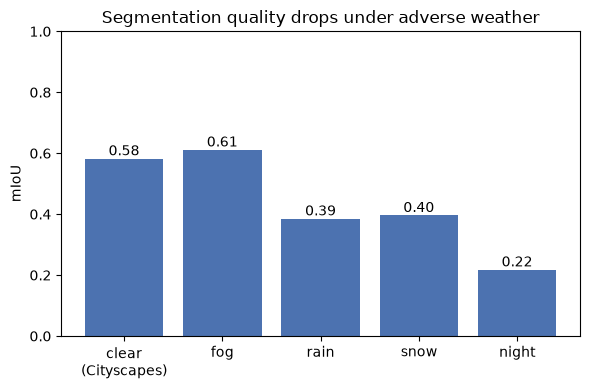

In [8]:
iou = pd.read_csv("../reports/week2_iou_per_class.csv", index_col=0)
order = ["clear", "fog", "rain", "snow", "night"]
miou = iou.loc["mIoU", order]

fig, ax = plt.subplots(figsize=(6, 4))
labels = ["clear\n(Cityscapes)", "fog", "rain", "snow", "night"]
bars = ax.bar(labels, miou, color="#4C72B0")
ax.bar_label(bars, fmt="%.2f")
ax.set_ylim(0, 1)
ax.set_ylabel("mIoU")
ax.set_title("Segmentation quality drops under adverse weather")
plt.tight_layout()
plt.savefig("../reports/figures/fig1_miou_per_condition.png", dpi=200)
plt.show()

100%|██████████| 106/106 [04:13<00:00,  2.39s/it]


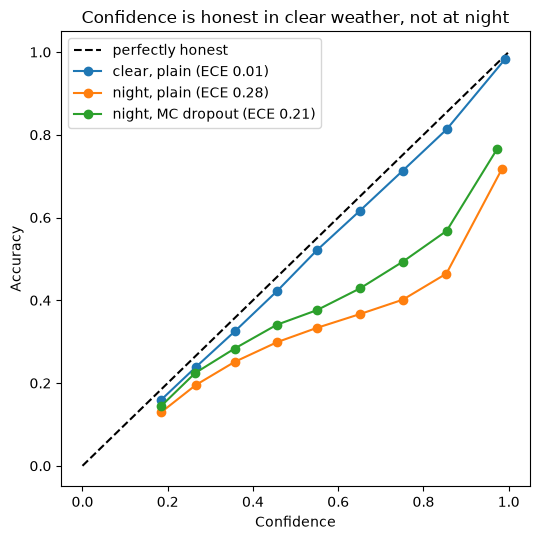

In [10]:
curves = [
    ("clear, plain", get_pairs("../data", "cityscapes"), predict),
    ("night, plain", night, predict),
    ("night, MC dropout", night, predict_mc),
]

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], "k--", label="perfectly honest")
for label, pairs, fn in curves:
    count, avg_conf, acc = reliability(pairs, processor, model, predict_fn=fn)
    ece = np.sum(count / count.sum() * np.abs(acc - avg_conf))
    ax.plot(avg_conf, acc, "o-", label=f"{label} (ECE {ece:.2f})")
ax.set_xlabel("Confidence")
ax.set_ylabel("Accuracy")
ax.set_title("Confidence is honest in clear weather, not at night")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/fig2_reliability.png", dpi=200)
plt.show()

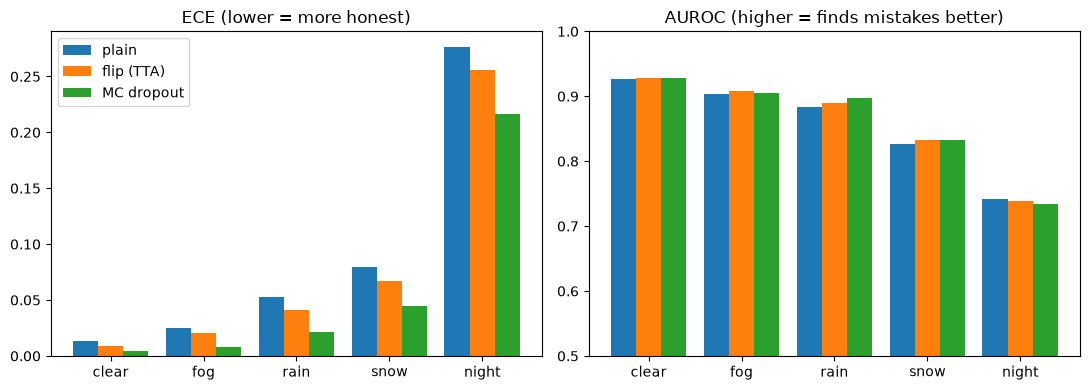

In [11]:
res = pd.read_csv("../reports/week4_results.csv")
order = ["clear", "fog", "rain", "snow", "night"]
methods = {"plain": "plain", "flip": "flip (TTA)", "mc": "MC dropout"}
x = np.arange(len(order))
width = 0.27

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
panels = [(axes[0], "ECE", "ECE (lower = more honest)"),
          (axes[1], "AUROC", "AUROC (higher = finds mistakes better)")]
for ax, metric, title in panels:
    for i, (m, nice) in enumerate(methods.items()):
        vals = res[res["method"] == m].set_index("condition").loc[order, metric]
        ax.bar(x + (i - 1) * width, vals, width, label=nice)
    ax.set_xticks(x)
    ax.set_xticklabels(order)
    ax.set_title(title)
axes[1].set_ylim(0.5, 1.0)
axes[0].legend()
plt.tight_layout()
plt.savefig("../reports/figures/fig3_methods_ece_auroc.png", dpi=200)
plt.show()

In [14]:
shares = []
for image_path, label_path in tqdm(night):
    image = Image.open(image_path).convert("RGB")
    label = load_label(label_path)
    pred, conf = predict(image, processor, model)
    valid = label != 255
    shares.append(((pred != label) & valid & (conf > .9)).sum() / valid.sum())
# the night photo with the most confident mistakes
i = int(np.argmax(shares))
print("image", i, "share of confidently wrong pixels:", round(shares[i], 2))

100%|██████████| 106/106 [00:42<00:00,  2.50it/s]

image 71 share of confidently wrong pixels: 0.41


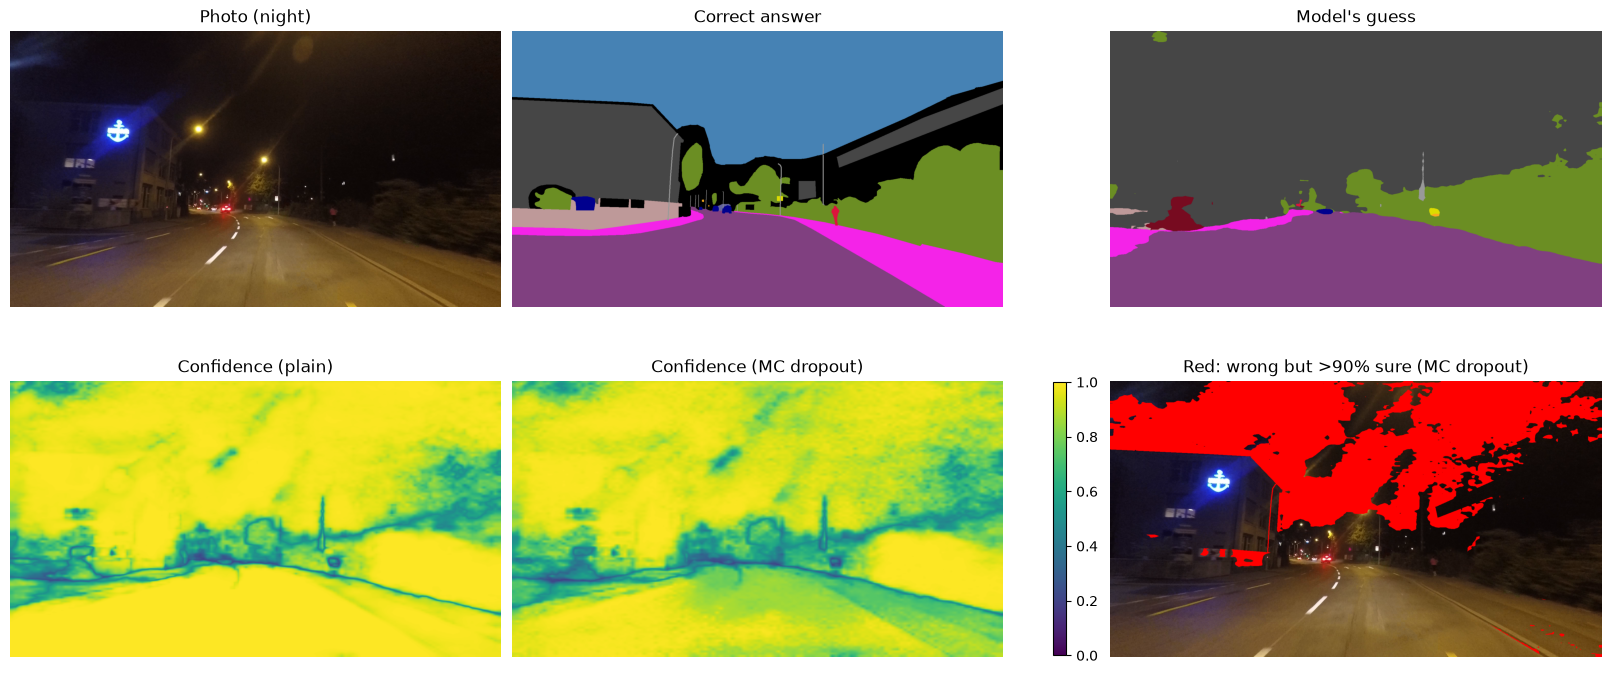

In [16]:
image_path, label_path = night[i]
image = Image.open(image_path).convert("RGB")
label = load_label(label_path)
pred, conf_plain = predict(image, processor, model)
pred_mc, conf_mc = predict_mc(image, processor, model)
valid = label != 255
hard = (pred_mc != label) & (conf_mc > 0.9) # wrong and >90% sure

overlay = np.array(image).copy()
overlay[hard] = [255, 0, 0]           # paint the hard core red

fig, axes = plt.subplots(2, 3, figsize=(16, 7), constrained_layout=True)
axes[0, 0].imshow(image)
axes[0, 0].set_title("Photo (night)")
axes[0, 1].imshow(palette_ext[np.where(label == 255, 19, label)])
axes[0, 1].set_title("Correct answer")
axes[0, 2].imshow(palette[pred])
axes[0, 2].set_title("Model's guess")
axes[1, 0].imshow(conf_plain, cmap="viridis", vmin=0, vmax=1)
axes[1, 0].set_title("Confidence (plain)")
im = axes[1, 1].imshow(conf_mc, cmap="viridis", vmin=0, vmax=1)
axes[1, 1].set_title("Confidence (MC dropout)")
axes[1, 2].imshow(overlay)
axes[1, 2].set_title("Red: wrong but >90% sure (MC dropout)")
fig.colorbar(im, ax=axes[1, :2], shrink=0.8)
for ax in axes.flat:
    ax.axis("off")
plt.savefig("../reports/figures/fig4_hard_core_example.png", dpi=200, bbox_inches="tight")
plt.show()